Notebook 3: Anomaly Detection

🚩 Detected 69 anomalous financial years across the index.


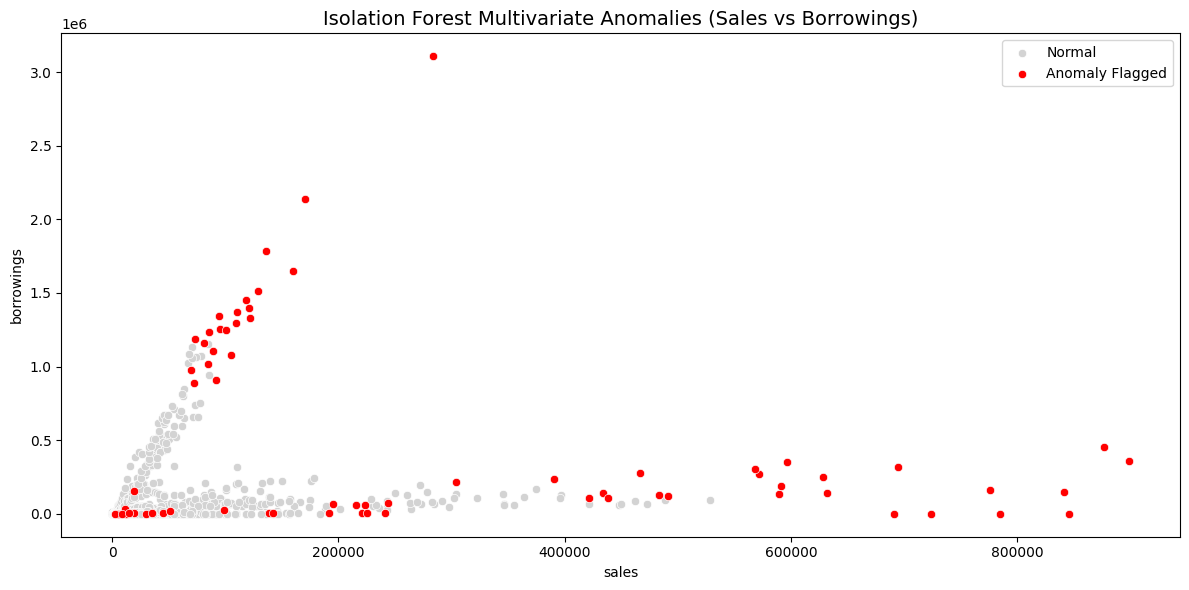

In [1]:
import pandas as pd
import numpy as np
from scipy.stats import zscore
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Clean Fact Tables
pl = pd.read_csv('../data/clean/clean_profit_loss.csv')
bs = pd.read_csv('../data/clean/clean_balance_sheet.csv')
df = pd.merge(pl, bs[['symbol', 'year_id', 'borrowings']], on=['symbol', 'year_id'])
df = df[df['year_label'] != 'TTM'].copy()

# 2. Z-Score Anomaly Detection (Threshold > 2.5)
# Flagging extreme YoY deviations in Sales, Net Profit, Operating Profit, and Borrowings
metrics = ['sales', 'net_profit', 'operating_profit', 'borrowings']
for m in metrics:
    df[f'{m}_zscore'] = df.groupby('symbol')[m].transform(lambda x: zscore(x, nan_policy='omit'))
    df[f'{m}_anomaly_z'] = abs(df[f'{m}_zscore']) > 2.5

# 3. Isolation Forest (Multivariate Anomaly Detection)
iso_features = df[metrics].fillna(0)
iso = IsolationForest(contamination=0.05, random_state=42)
df['iso_outlier'] = iso.fit_predict(iso_features)
df['is_multivariate_anomaly'] = df['iso_outlier'] == -1

# 4. Extract & Visualize High-Severity Anomalies
anomalies = df[(df['is_multivariate_anomaly']) | (df['borrowings_anomaly_z'])].copy()
print(f"🚩 Detected {len(anomalies)} anomalous financial years across the index.")

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='sales', y='borrowings', color='lightgrey', label='Normal')
sns.scatterplot(data=anomalies, x='sales', y='borrowings', color='red', label='Anomaly Flagged')
plt.title('Isolation Forest Multivariate Anomalies (Sales vs Borrowings)', fontsize=14)
plt.legend()
plt.tight_layout()
plt.show()

# Export for the Django Admin Dashboard
anomalies[['symbol', 'year_label'] + metrics + ['is_multivariate_anomaly']].to_csv('../data/fact_anomaly_flags.csv', index=False)